# AgriPulse ML — Predicting Crop Yield Performance using Classification Models (KNN vs Random Forest)

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import warnings
warnings.filterwarnings("ignore")

In [2]:
# Q1. Load the cleaned Crop Yield dataset. Identify the Type of ML Problem. Select 'Yield_category' as target variable.print the shape of X 
#     and y. 

In [3]:
crop = pd.read_csv('Crop_Production.csv')
climate = pd.read_csv('Climate_Agriculture.csv')
df = crop.merge(climate, on='Record_ID')

print("Merged dataset shape:", df.shape)

Merged dataset shape: (19689, 17)


In [4]:
print("Target classes:", df['Yield_Category'].unique())
print("This is a MULTI-CLASS CLASSIFICATION problem "
      "(target has discrete categories: Low, Medium, High, Very High)")

Target classes: ['Low' 'Very High' 'High' 'Medium']
This is a MULTI-CLASS CLASSIFICATION problem (target has discrete categories: Low, Medium, High, Very High)


In [5]:
target = 'Yield_Category'
X = df.drop(columns=['Record_ID', target])   
y = df[target]

In [6]:
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (19689, 15)
Shape of y: (19689,)


In [7]:
# Q2.Identify categorical and Numeric columns. Apply Encoding techniques (if necessary).perform Standard Scaling on numerical 
#    features. Display the final processed data. 

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder

In [9]:
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

In [10]:
print("Categorical columns:", categorical_cols)
print("Numeric columns:", numeric_cols)

Categorical columns: ['Season', 'State', 'Crop', 'Rainfall_Category', 'Year_Group']
Numeric columns: ['Crop_Year', 'Area', 'Production', 'Yield', 'Production_per_Area', 'Annual_Rainfall', 'Fertilizer', 'Fertilizer_per_Area', 'Pesticide', 'Pesticide_per_Area']


In [11]:
X_encoded = X.copy()
for col in categorical_cols:
    le = LabelEncoder()
    X_encoded[col] = le.fit_transform(X_encoded[col])

In [12]:
scaler = StandardScaler()
X_scaled = X_encoded.copy()
X_scaled[numeric_cols] = scaler.fit_transform(X_encoded[numeric_cols])

In [13]:
print("Final processed data (first 5 rows):")
print(X_scaled.head())

Final processed data (first 5 rows):
   Crop_Year  Season  State      Area  Production     Yield  \
0  -1.866375       4      2 -0.134865   -0.061023 -0.090513   
1  -1.866375       1      2 -0.228365   -0.061228 -0.090612   
2  -1.866375       1      2 -0.235122   -0.061246 -0.091163   
3  -1.866375       4      2 -0.210245    0.436977  9.552233   
4  -1.866375       1      2 -0.235182   -0.061243 -0.090950   

   Production_per_Area  Crop  Annual_Rainfall  Rainfall_Category  Fertilizer  \
0            -0.090640     0         0.757055                  0   -0.208577   
1            -0.090708     1         0.757055                  0   -0.224177   
2            -0.091446     8         0.757055                  0   -0.225533   
3             6.931092     9         0.757055                  0   -0.221154   
4            -0.090979    11         0.757055                  0   -0.225314   

   Fertilizer_per_Area  Pesticide  Pesticide_per_Area  Year_Group  
0            -1.602681  -0.121745  

In [14]:
# Q.3.Plot distribution of the yield_category column. Analyse the relationship between Rainfall and yield_category, Temperature and 
#    yield_category, Area and yield_category.

In [15]:
df['Yield_Category'] = df['Yield_Category'].astype(str).str.strip()
target = 'Yield_Category'

In [16]:
order = [cat for cat in ['Low', 'Medium', 'High', 'Very High'] 
         if cat in df[target].unique()]
print("Using order:", order)

Using order: ['Low', 'Medium', 'High', 'Very High']


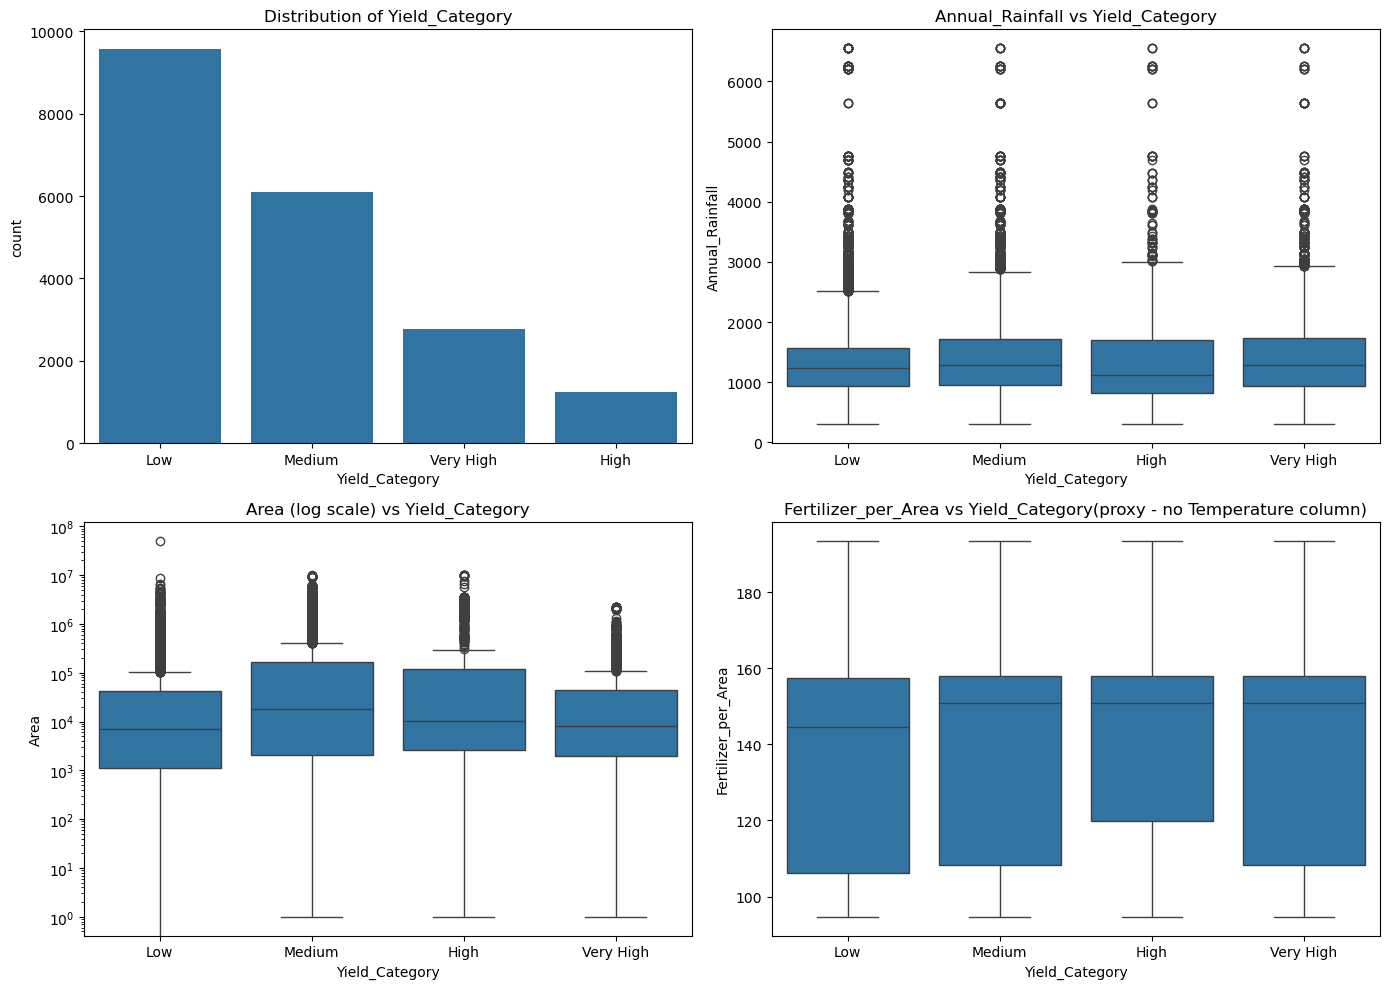

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(x=target, data=df, order=df[target].value_counts().index, ax=axes[0, 0])
axes[0, 0].set_title('Distribution of Yield_Category')

sns.boxplot(x=target, y='Annual_Rainfall', data=df, order=order, ax=axes[0, 1])
axes[0, 1].set_title('Annual_Rainfall vs Yield_Category')

sns.boxplot(x=target, y='Area', data=df, order=order, ax=axes[1, 0])
axes[1, 0].set_yscale('log')
axes[1, 0].set_title('Area (log scale) vs Yield_Category')

sns.boxplot(x=target, y='Fertilizer_per_Area', data=df, order=order, ax=axes[1, 1])
axes[1, 1].set_title('Fertilizer_per_Area vs Yield_Category(proxy - no Temperature column)')

plt.tight_layout()
plt.savefig('yield_category_analysis.png', dpi=120)
plt.show()

In [24]:
# Q.4 Split the dataset into training and testing sets. Train a KNN model and find best accuracy point by using Elbow method. Display accuracy 
#    Score, Confusion Matrix, Classification Report.

In [25]:
cat_cols = X.select_dtypes(include=['object']).columns.tolist()
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

X_encoded = X.copy()
for col in cat_cols:
    X_encoded[col] = LabelEncoder().fit_transform(X_encoded[col])

In [26]:
scaler = StandardScaler()
X_scaled = X_encoded.copy()
X_scaled[num_cols] = scaler.fit_transform(X_encoded[num_cols])

y_encoder = LabelEncoder()
y_encoded = y_encoder.fit_transform(y)

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

Train shape: (15751, 15) Test shape: (3938, 15)


In [29]:
k_range = range(1, 21)
accuracies = []
for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    accuracies.append(accuracy_score(y_test, knn.predict(X_test)))

In [30]:
best_k = list(k_range)[np.argmax(accuracies)]
print(f"Best K (Elbow point): {best_k}, Accuracy: {max(accuracies):.4f}")

Best K (Elbow point): 3, Accuracy: 0.8212


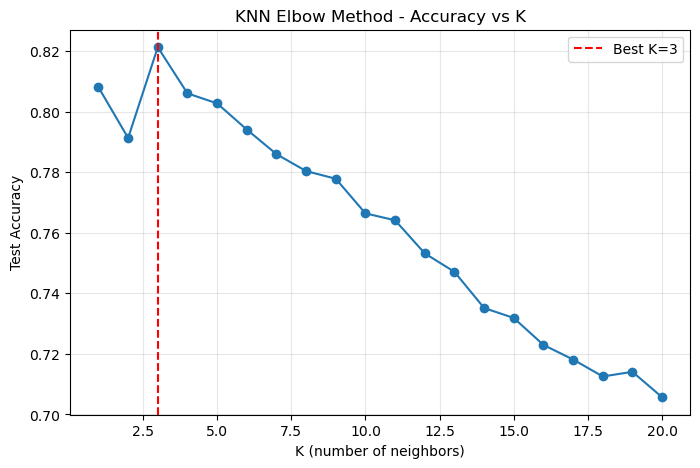

In [31]:
plt.figure(figsize=(8, 5))
plt.plot(list(k_range), accuracies, marker='o')
plt.axvline(best_k, color='red', linestyle='--', label=f'Best K={best_k}')
plt.xlabel('K (number of neighbors)')
plt.ylabel('Test Accuracy')
plt.title('KNN Elbow Method - Accuracy vs K')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('knn_elbow.png', dpi=120)
plt.show()

In [32]:
knn_final = KNeighborsClassifier(n_neighbors=best_k)
knn_final.fit(X_train, y_train)
knn_pred = knn_final.predict(X_test)

In [33]:
print("Accuracy Score:", accuracy_score(y_test, knn_pred))
print("Confusion Matrix:", confusion_matrix(y_test, knn_pred))
print("Classification Report:",
      classification_report(y_test, knn_pred, target_names=y_encoder.classes_))

Accuracy Score: 0.8212290502793296
Confusion Matrix: [[ 169   23   40   17]
 [  36 1665  190   24]
 [  50  207  945   17]
 [  41   37   22  455]]
Classification Report:               precision    recall  f1-score   support

        High       0.57      0.68      0.62       249
         Low       0.86      0.87      0.87      1915
      Medium       0.79      0.78      0.78      1219
   Very High       0.89      0.82      0.85       555

    accuracy                           0.82      3938
   macro avg       0.78      0.79      0.78      3938
weighted avg       0.82      0.82      0.82      3938



In [34]:
#Q5. Train a Random Forest Classifier on the same data and predict sales_category.find - accuracy Score, Confusion Matrix, Classification 
#    Report.Compare Performance of KNN and Random Forest. 

In [36]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

In [37]:
rf_acc = accuracy_score(y_test, rf_pred)
rf_cm = confusion_matrix(y_test, rf_pred)
rf_report = classification_report(y_test, rf_pred, target_names=y_encoder.classes_)

In [38]:
print("Random Forest Accuracy Score:", rf_acc)
print("Confusion Matrix:", rf_cm)
print("Classification Report:", rf_report)


Random Forest Accuracy Score: 0.9832402234636871
Confusion Matrix: [[ 225    3   15    6]
 [   0 1911    4    0]
 [   5   23 1189    2]
 [   3    3    2  547]]
Classification Report:               precision    recall  f1-score   support

        High       0.97      0.90      0.93       249
         Low       0.99      1.00      0.99      1915
      Medium       0.98      0.98      0.98      1219
   Very High       0.99      0.99      0.99       555

    accuracy                           0.98      3938
   macro avg       0.98      0.97      0.97      3938
weighted avg       0.98      0.98      0.98      3938



In [39]:
knn = KNeighborsClassifier(n_neighbors=3)   # Q4 me best_k = 3 mila tha
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)
knn_acc = accuracy_score(y_test, knn_pred)
knn_cm = confusion_matrix(y_test, knn_pred)

In [40]:
print("COMPARISON -> KNN Accuracy: {knn_acc:.4f}  |  Random Forest Accuracy: {rf_acc:.4f}")
winner = "Random Forest" if rf_acc > knn_acc else "KNN"
print("Better performing model: {winner}")

COMPARISON -> KNN Accuracy: {knn_acc:.4f}  |  Random Forest Accuracy: {rf_acc:.4f}
Better performing model: {winner}


In [41]:
importances = pd.Series(rf.feature_importances_, index=X_scaled.columns).sort_values(ascending=False)
print("Top 5 important features (Random Forest):")
print(importances.head())

Top 5 important features (Random Forest):
Yield                  0.477719
Production_per_Area    0.309269
Production             0.062825
Season                 0.028673
Area                   0.022380
dtype: float64


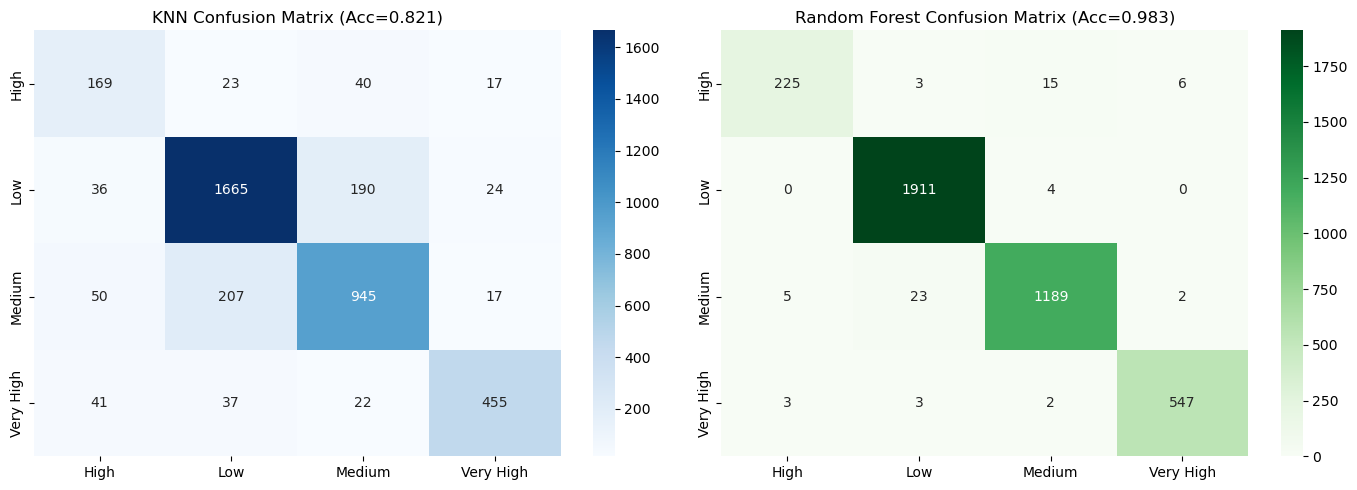

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(knn_cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=y_encoder.classes_, yticklabels=y_encoder.classes_)
axes[0].set_title(f'KNN Confusion Matrix (Acc={knn_acc:.3f})')
sns.heatmap(rf_cm, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=y_encoder.classes_, yticklabels=y_encoder.classes_)
axes[1].set_title(f'Random Forest Confusion Matrix (Acc={rf_acc:.3f})')
plt.tight_layout()
plt.savefig('model_comparison_confusion_matrices.png', dpi=120)
plt.show()